In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os
import seaborn as sns
sns.set()

#### Read all files into list of DFs for each month. Add month and year value to each.

In [2]:
file_list = glob.glob("./DATA/*.csv")
df_list = []


for file in file_list:
    file_name = os.path.basename(file)
    df = pd.read_csv(file)
    
    year = int(file_name[0:4])
    month = int(file_name[4:6])

    df["year"] = year
    df["month"] = month

    df = df[df['tripduration'] < 14400]
    df_list.append(df)

combined = pd.concat(df_list, ignore_index=True)
print(len(df_list))

12


### Column Names, use for calculations:

In [3]:
print(combined.columns.tolist())

['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual', 'tripduration', 'year', 'month']


In [4]:
combined['started_at'] = pd.to_datetime(combined['started_at'])
combined['ended_at'] = pd.to_datetime(combined['ended_at'])

In [5]:
mean_trips_month = []
np.set_printoptions(suppress=True, floatmode='fixed')

for df in df_list:
    mean_trips_month.append((np.mean(df['tripduration']), df['month'][0]))

trip_duration_means = np.array(mean_trips_month, dtype=float)
trip_duration_means = trip_duration_means[trip_duration_means[:, 1].argsort()]
print (trip_duration_means)

[[677.95592252   1.00000000]
 [689.43463777   2.00000000]
 [797.61575509   3.00000000]
 [874.87986282   4.00000000]
 [928.49916375   5.00000000]
 [955.11714959   6.00000000]
 [986.47284528   7.00000000]
 [980.59856209   8.00000000]
 [887.78110569   9.00000000]
 [850.80876115  10.00000000]
 [767.17994831  11.00000000]
 [704.47849274  12.00000000]]


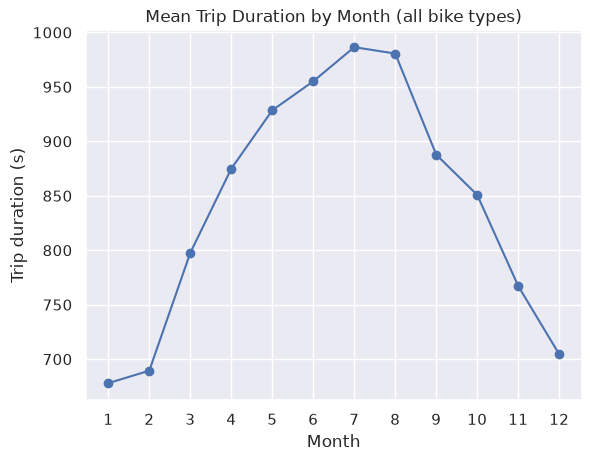

In [7]:
x, y = trip_duration_means[:, 1], trip_duration_means[:, 0] 
plt.plot(x, y, marker="o")
plt.xlabel("Month")
plt.ylabel("Trip duration (s)")
plt.title("Mean Trip Duration by Month (all bike types)")
plt.grid(True)
plt.xticks(np.arange(1, 13, 1))
plt.show()

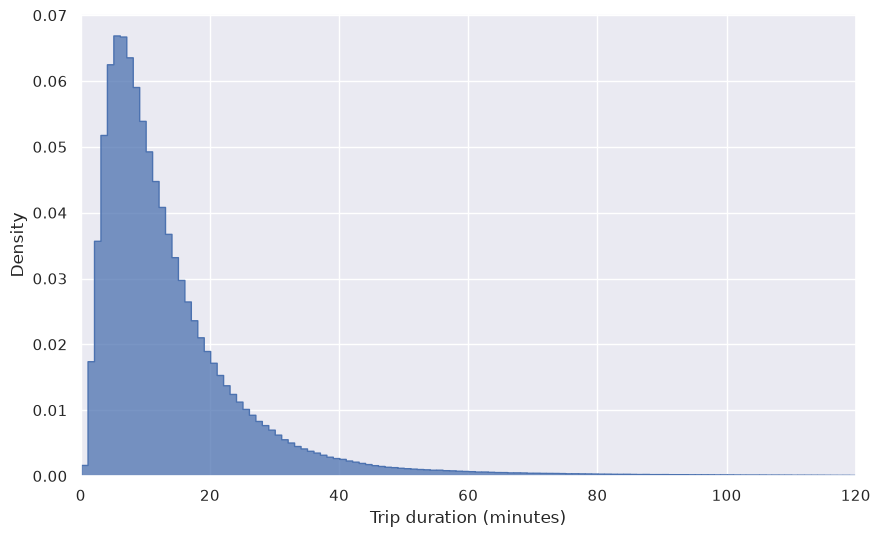

In [8]:
combined['duration_min'] = combined['tripduration'] / 60

plt.figure(figsize=(10, 6))
sns.histplot(
    data=combined, x='duration_min',
    stat='density', common_norm=False,
    element='step', binwidth=1, kde=False
)
plt.xlim(0, 120)
plt.xlabel('Trip duration (minutes)')
plt.show()

Mean: 1.1397359985106874, Median: 0.9303779028300737, IQR: 0.9187273952327815, Range: 8.292129895683997


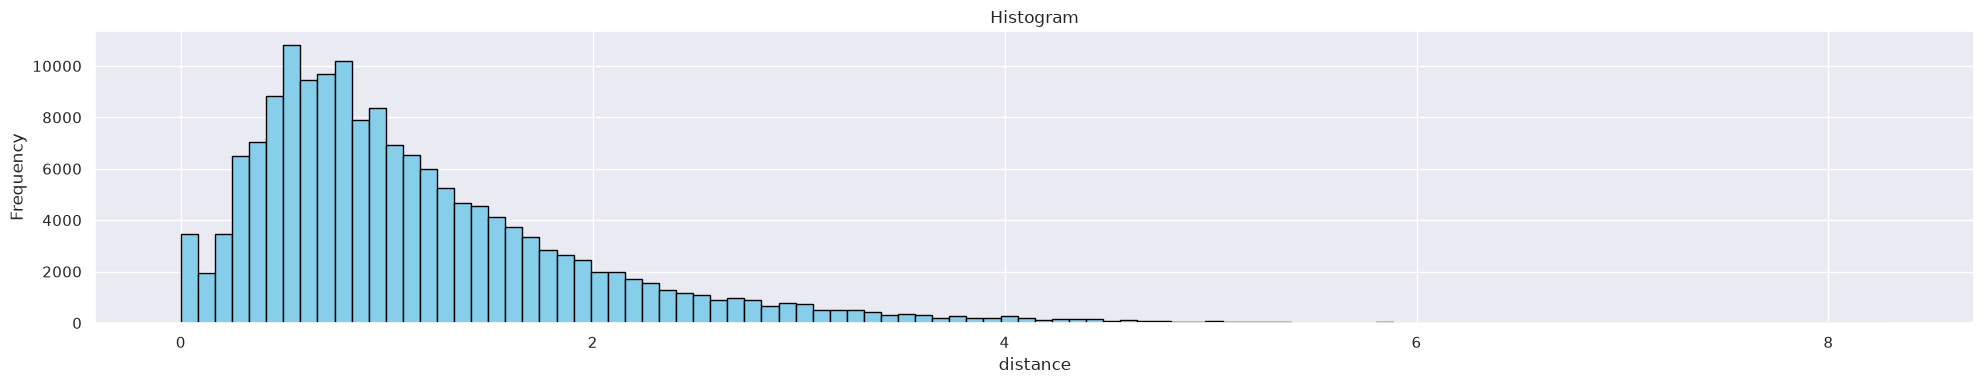

In [6]:
def haversine_vectorized(lat1, lon1, lat2, lon2, unit="miles"):
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))

    # Earth radius
    radius = 3959 if unit == "miles" else 6371

    return c * radius


# Calculate instantly across all rows
distance = haversine_vectorized(
    df["start_lat"], df["start_lng"], df["end_lat"], df["end_lng"], unit="miles"
)

pd_mean = distance.mean()
pd_median = distance.median()
q1_pd = distance.quantile(0.25)
q3_pd = distance.quantile(0.75)
pd_iqr = q3_pd - q1_pd
pd_range = distance.max() - distance.min()

print(f"Mean: {pd_mean}, Median: {pd_median}, IQR: {pd_iqr}, Range: {pd_range}")

fig, ax = plt.subplots(figsize=(20, 4))


ax.hist(distance, bins=100, color="skyblue", edgecolor="black")
ax.set_title("Histogram")
ax.set_xlabel("distance")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [9]:
electric = combined[combined['rideable_type'] == 'electric_bike']
classic = combined[combined['rideable_type'] == 'classic_bike']

electric_duration_mean = np.mean(electric['tripduration'])
classic_duration_mean = np.mean(classic['tripduration'])

In [50]:
monthly_means_elec = electric.groupby('month')['tripduration'].mean()
monthly_means_classic = classic.groupby('month')['tripduration'].mean()

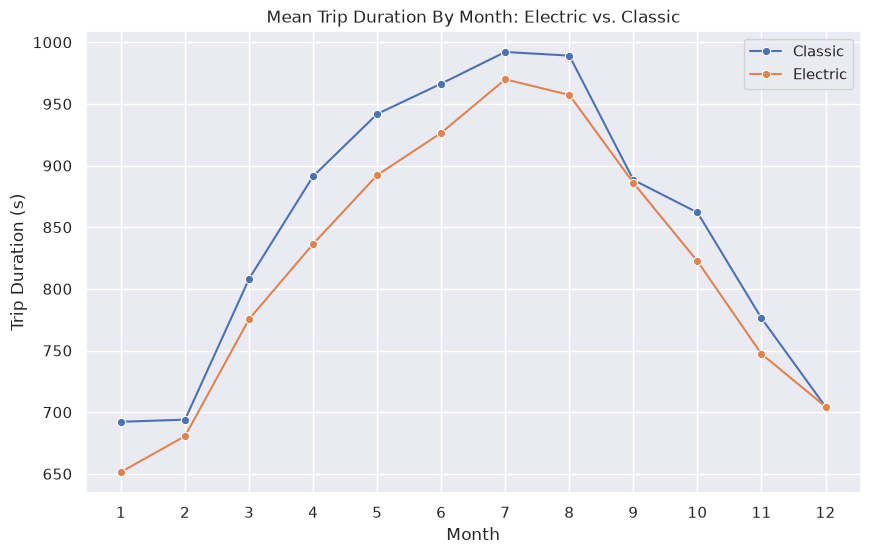

In [51]:
plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_means_classic.index, y=monthly_means_classic.values, label='Classic', marker='o')
sns.lineplot(x=monthly_means_elec.index, y=monthly_means_elec.values, label='Electric', marker='o')

plt.xlabel('Month')
plt.ylabel('Trip Duration (s)')
plt.title('Mean Trip Duration By Month: Electric vs. Classic')
plt.xticks(range(1, 13)) 
plt.legend()
plt.show()

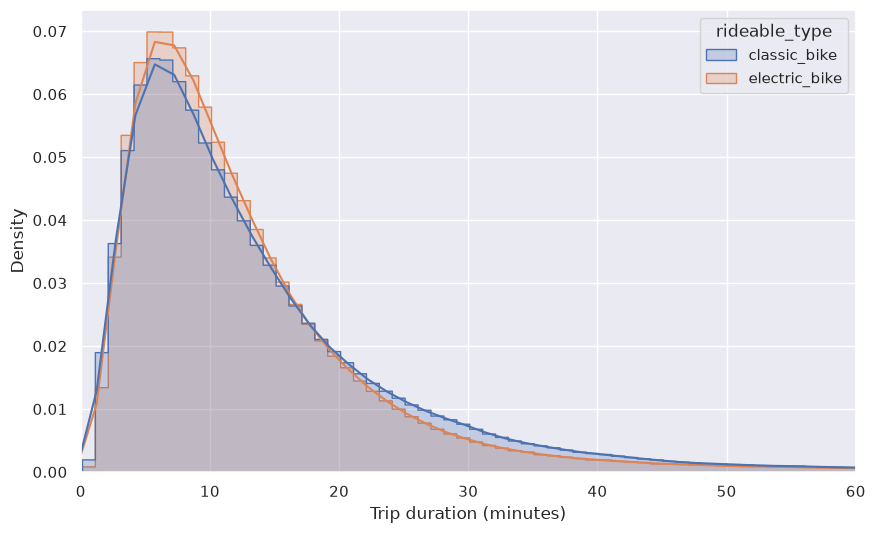

In [13]:
combined['duration_min'] = combined['tripduration'] / 60

plt.figure(figsize=(10, 6))
sns.histplot(
    data=combined, x='duration_min', hue='rideable_type',
    stat='density', common_norm=False,
    element='step', binwidth=1, kde=True
)
plt.xlim(0, 60)  # zoom in on where most trips are
plt.xlabel('Trip duration (minutes)')
plt.show()

In [52]:
monthly_counts = combined.groupby(combined['month']).size()

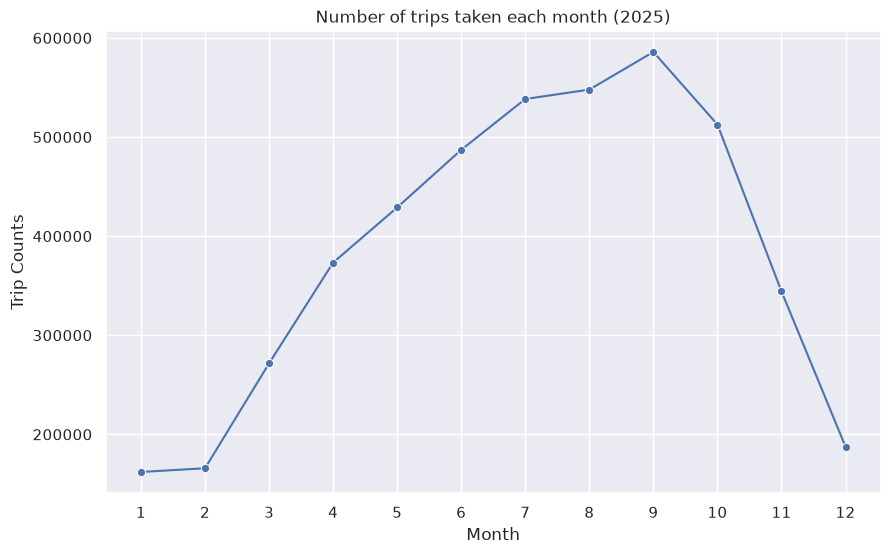

In [16]:
plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_counts.index, y=monthly_counts.values, marker='o')

plt.xlabel('Month')
plt.ylabel('Trip Counts')
plt.title('Number of trips taken each month (2025)')
plt.xticks(range(1, 13)) 
plt.show()

### Likely peak in september from students coming / returning to Boston for school.

In [44]:
station_counts = (
    combined['start_station_name'].value_counts()
    .add(combined['end_station_name'].value_counts(), fill_value=0)
    .astype(int)
    .sort_values(ascending=False)
)

top = station_counts.head(15)
bottom = station_counts.tail(16)[::-1][1:]


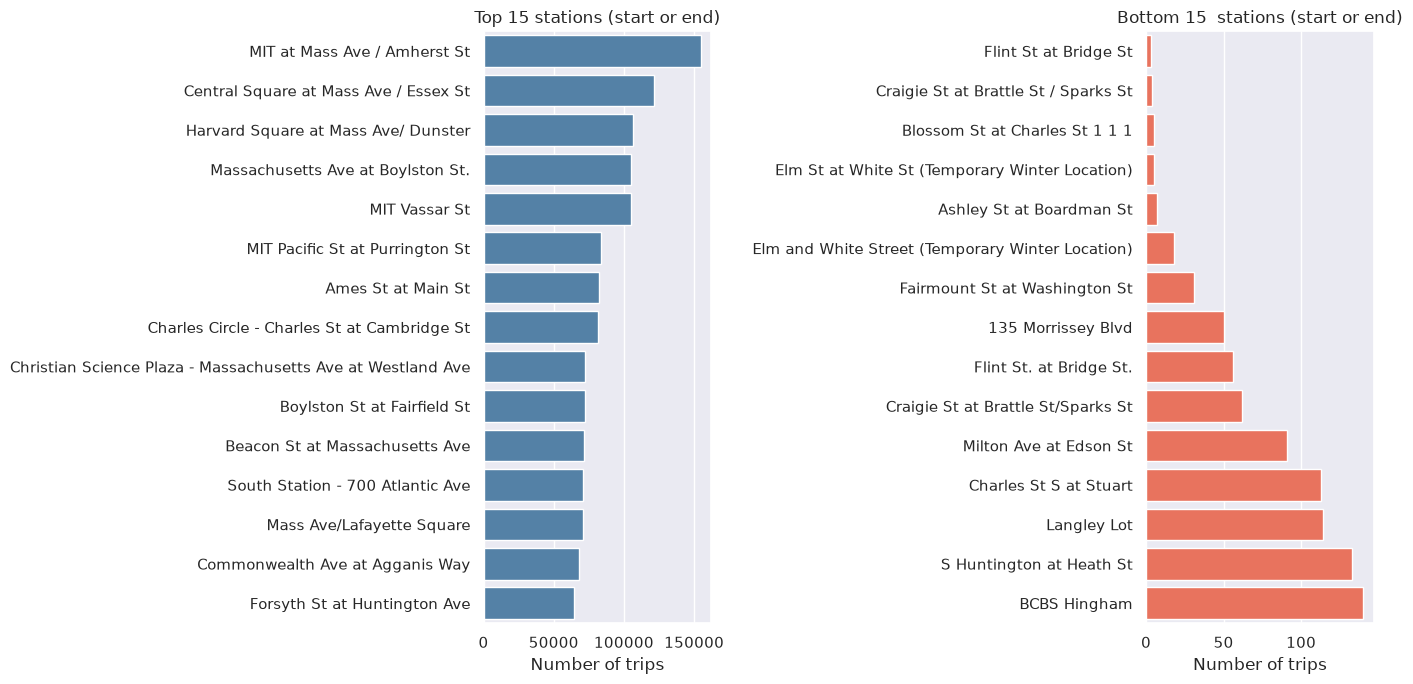

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
sns.barplot(x=top.values, y=top.index, ax=axes[0], color='steelblue')
axes[0].set_title('Top 15 stations (start or end)')
sns.barplot(x=bottom.values, y=bottom.index, ax=axes[1], color='tomato')
axes[1].set_title('Bottom 15  stations (start or end)')
for ax in axes:
    ax.set_xlabel('Number of trips')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [24]:
round_trips = combined[combined['start_station_id'] == combined['end_station_id']]
point_to_point = combined[combined['start_station_id'] != combined['end_station_id']]

In [48]:
top_pairs = (
    point_to_point.groupby(['start_station_name', 'end_station_name'])
                  .size()
                  .sort_values(ascending=False)
                  .head(10)
                  .reset_index(name='trips')
)

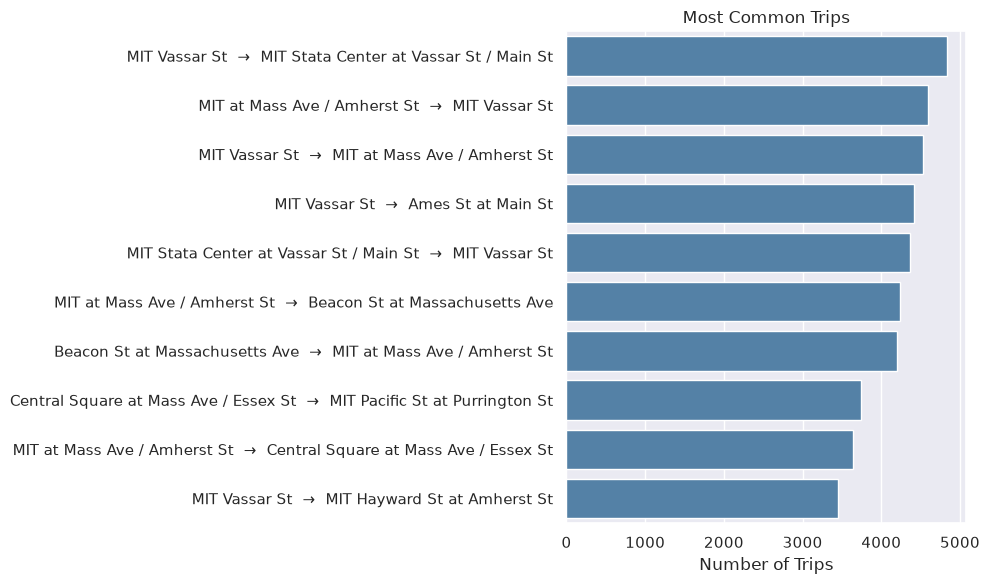

In [49]:
top = top_pairs.copy()
top['label'] = top['start_station_name'] + '  →  ' + top['end_station_name']

plt.figure(figsize=(10, 6))
sns.barplot(data=top, x='trips', y='label', color='steelblue')
plt.xlabel('Number of Trips')
plt.ylabel('')
plt.title('Most Common Trips')
plt.tight_layout()
plt.show()

In [53]:
trips_by_hour = (
    combined.groupby(combined['started_at'].dt.hour)
            .size()
            .rename('trips')
)


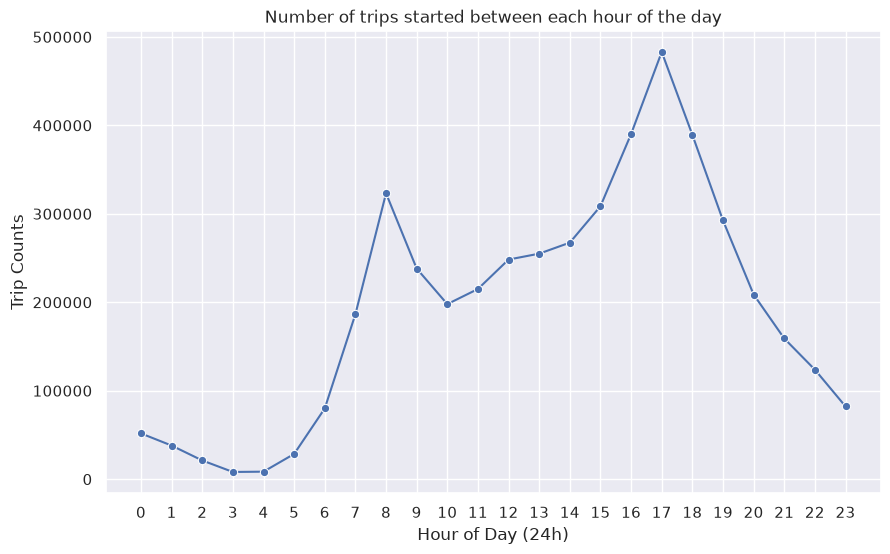

In [54]:
plt.figure(figsize=(10, 6))
sns.lineplot(x=trips_by_hour.index, y=trips_by_hour.values, marker='o')

plt.xlabel('Hour of Day (24h)')
plt.ylabel('Trip Counts')
plt.title('Number of trips started between each hour of the day')
plt.xticks(range(0, 24)) 
plt.show()